# ۰۸ · مبانی تنسورها؛ NumPy، TensorFlow و PyTorch

در این درس ساختن تنسور، دیدن مشخصات، انتخاب عناصر، تغییر شکل، محاسبه و تبدیل بین کتابخانه‌ها را یاد می‌گیریم.
مثال‌های هر سه کتابخانه کنار هم آمده‌اند. زمان پیشنهادی تدریس: ۹۰ تا ۱۲۰ دقیقه.

**روش مطالعه:** سلول‌ها را از بالا به پایین اجرا کنید. هر بخش یک مفهوم کوچک و یک مثال دارد.
پیش‌نیاز فقط آشنایی مقدماتی با پایتون و لیست است. خروجی‌های فایل از اجرای واقعی کدها ذخیره شده‌اند.
این درس برای اجرا روی CPU نوشته شده است.

<style>
.jp-MarkdownOutput,.text_cell_render {direction:rtl;text-align:right;font-family:Tahoma,Arial,sans-serif;line-height:1.9}
.jp-MarkdownOutput pre,.text_cell_render pre,.jp-CodeCell,.jp-OutputArea-output {direction:ltr;text-align:left}
mjx-container,.MathJax {direction:ltr} table {direction:ltr}
</style>

## ۱. تنسور چیست؟

تنسور در این درس یک آرایهٔ چندبعدی از عددهاست. ساده‌ترین نمونه‌ها:

| نام | مثال | شکل یا shape | تعداد محور یا rank |
|---|---|---|---|
| عدد یا scalar | `5` | `()` | ۰ |
| بردار | `[1, 2, 3]` | `(3,)` | ۱ |
| ماتریس | دو سطر و سه ستون | `(2, 3)` | ۲ |
| دسته‌ای از تصویرها | ۱۰ تصویر رنگی ۲۸×۲۸ | `(10, 28, 28, 3)` | ۴ |

منظور از rank اینجا تعداد محورهای آرایه است؛ با رتبهٔ ماتریس در جبر خطی فرق دارد.
`shape` اندازهٔ هر محور را می‌گوید. در شکل `(2, 3)` دو سطر و سه ستون داریم، یعنی ۶ عدد.

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import numpy as np
import tensorflow as tf
import torch
import matplotlib.pyplot as plt

np.random.seed(42)
tf.random.set_seed(42)
torch.manual_seed(42)
torch.set_num_threads(2)

print('NumPy:', np.__version__)
print('TensorFlow:', tf.__version__)
print('PyTorch:', torch.__version__)

C:\Program Files\Python311\Lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.5.0) or chardet (7.6.0)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(


NumPy: 2.2.6
TensorFlow: 2.20.0
PyTorch: 2.9.1+cpu


In [2]:
a_np = np.array([[1, 2, 3], [4, 5, 6]])
a_tf = tf.constant([[1, 2, 3], [4, 5, 6]])
a_pt = torch.tensor([[1, 2, 3], [4, 5, 6]])

print('NumPy:\n', a_np)
print('TensorFlow:\n', a_tf)
print('PyTorch:\n', a_pt)

NumPy:
 [[1 2 3]
 [4 5 6]]
TensorFlow:
 tf.Tensor(
[[1 2 3]
 [4 5 6]], shape=(2, 3), dtype=int32)
PyTorch:
 tensor([[1, 2, 3],
        [4, 5, 6]])


## ۲. دیدن شکل، نوع و تعداد عناصر

سه مشخصه را عادت کنید همیشه بررسی کنید: **shape، dtype و device**.
`dtype` نوع عدد و `device` محل محاسبه است. تعداد عناصر حاصل‌ضرب اندازهٔ محور‌هاست.
در TensorFlow از `tf.size` و در PyTorch از `numel` برای تعداد عناصر استفاده می‌کنیم.
در NumPy ویژگی `size` تعداد عناصر است؛ در PyTorch، `size()` شکل را می‌دهد، پس این دو را اشتباه نگیرید.

In [3]:
print('NumPy:', a_np.shape, a_np.ndim, a_np.dtype, a_np.size)
print('TensorFlow:', a_tf.shape, tf.rank(a_tf).numpy(), a_tf.dtype, tf.size(a_tf).numpy())
print('PyTorch:', a_pt.shape, a_pt.ndim, a_pt.dtype, a_pt.numel())
print('TF device:', a_tf.device)
print('Torch device:', a_pt.device)

print('NumPy bytes:', a_np.nbytes)
print('Torch bytes:', a_pt.numel() * a_pt.element_size())

NumPy: (2, 3) 2 int64 6
TensorFlow: (2, 3) 2 <dtype: 'int32'> 6
PyTorch: torch.Size([2, 3]) 2 torch.int64 6
TF device: /job:localhost/replica:0/task:0/device:CPU:0
Torch device: cpu
NumPy bytes: 48
Torch bytes: 48


## ۳. ساخت صفر، یک، مقدار ثابت و دنباله

شکل را داخل پرانتز می‌نویسیم. `(2, 3)` یعنی دو سطر و سه ستون.
در `arange(start, stop)` عدد انتهایی وارد خروجی نمی‌شود؛ در مثال ما اعداد ۰ تا ۵ ساخته می‌شوند.

In [4]:
print('Zeros:')
print(np.zeros((2, 3)))
print(tf.zeros((2, 3)))
print(torch.zeros((2, 3)))

print('Ones:', np.ones(3), tf.ones(3), torch.ones(3))
print('Constant:', np.full((2, 2), 7), tf.fill((2, 2), 7), torch.full((2, 2), 7))
print('Range:', np.arange(6), tf.range(6), torch.arange(6))
print('Linspace:', np.linspace(0, 1, 5), tf.linspace(0., 1., 5), torch.linspace(0, 1, 5))
print('Identity matrix:\n', np.eye(3), '\n', tf.eye(3), '\n', torch.eye(3))

Zeros:
[[0. 0. 0.]
 [0. 0. 0.]]
tf.Tensor(
[[0. 0. 0.]
 [0. 0. 0.]], shape=(2, 3), dtype=float32)
tensor([[0., 0., 0.],
        [0., 0., 0.]])
Ones: [1. 1. 1.] tf.Tensor([1. 1. 1.], shape=(3,), dtype=float32) tensor([1., 1., 1.])
Constant: [[7 7]
 [7 7]] tf.Tensor(
[[7 7]
 [7 7]], shape=(2, 2), dtype=int32) tensor([[7, 7],
        [7, 7]])
Range: [0 1 2 3 4 5] tf.Tensor([0 1 2 3 4 5], shape=(6,), dtype=int32) tensor([0, 1, 2, 3, 4, 5])
Linspace: [0.   0.25 0.5  0.75 1.  ] tf.Tensor([0.   0.25 0.5  0.75 1.  ], shape=(5,), dtype=float32) tensor([0.0000, 0.2500, 0.5000, 0.7500, 1.0000])
Identity matrix:
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]] 
 tf.Tensor(
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]], shape=(3, 3), dtype=float32) 
 tensor([[1., 0., 0.],
        [0., 1., 0.],
        [0., 0., 1.]])


## ۴. عدد تصادفی و seed

اعداد یکنواخت زیر در بازهٔ صفر تا یک ساخته می‌شوند. `normal` یا `randn` برای توزیع نرمال است.
seed برای تکرارپذیری استفاده می‌شود. یک seed یکسان در سه کتابخانه الزاماً عددهای یکسان تولید نمی‌کند.

In [5]:
print('Uniform:')
print(np.random.rand(2, 3))
print(tf.random.uniform((2, 3)))
print(torch.rand(2, 3))

print('Normal:')
print(np.random.randn(3))
print(tf.random.normal((3,)))
print(torch.randn(3))

Uniform:
[[0.37454012 0.95071431 0.73199394]
 [0.59865848 0.15601864 0.15599452]]
tf.Tensor(
[[0.6645621  0.44100678 0.3528825 ]
 [0.46448255 0.03366041 0.68467236]], shape=(2, 3), dtype=float32)
tensor([[0.8823, 0.9150, 0.3829],
        [0.9593, 0.3904, 0.6009]])
Normal:
[ 1.57921282  0.76743473 -0.46947439]
tf.Tensor([ 0.08422458 -0.86090374  0.37812304], shape=(3,), dtype=float32)
tensor([ 1.1561,  0.3965, -2.4661])


## ۵. dtype و تبدیل نوع

برای ورودی شبکه معمولاً `float32` مناسب است. برای شناسهٔ کلاس در PyTorch از `long` یا همان `int64` استفاده می‌کنیم.
نوع پیش‌فرض عدد صحیح ممکن است بین کتابخانه‌ها فرق کند؛ آن را صریح مشخص کنید.
تبدیل عدد اعشاری به صحیح، بخش اعشاری را حذف می‌کند و ممکن است اطلاعات را از بین ببرد.

In [6]:
f_np = a_np.astype(np.float32)
f_tf = tf.cast(a_tf, tf.float32)
f_pt = a_pt.to(torch.float32)  # a_pt.float() هم همین کاربرد را دارد

print(f_np.dtype, f_tf.dtype, f_pt.dtype)
print(np.array([1.8, -2.7]).astype(np.int32))
print(tf.cast([1.8, -2.7], tf.int32))
print(torch.tensor([1.8, -2.7]).to(torch.int32))

float32 <dtype: 'float32'> torch.float32
[ 1 -2]
tf.Tensor([ 1 -2], shape=(2,), dtype=int32)
tensor([ 1, -2], dtype=torch.int32)


## ۶. انتخاب عنصر و برش

شماره‌گذاری از صفر شروع می‌شود. `[0, 1]` یعنی سطر اول، ستون دوم.
`:` یعنی همهٔ عناصر آن محور. انتهای برش هم مانند پایتون وارد خروجی نمی‌شود.

In [7]:
print('One element:', a_np[0, 1], a_tf[0, 1].numpy(), a_pt[0, 1].item())
print('First row:', a_np[0], a_tf[0], a_pt[0])
print('Second column:', a_np[:, 1], a_tf[:, 1], a_pt[:, 1])
print('First two columns:\n', a_np[:, :2], '\n', a_tf[:, :2], '\n', a_pt[:, :2])

One element: 2 2 2
First row: [1 2 3] tf.Tensor([1 2 3], shape=(3,), dtype=int32) tensor([1, 2, 3])
Second column: [2 5] tf.Tensor([2 5], shape=(2,), dtype=int32) tensor([2, 5])
First two columns:
 [[1 2]
 [4 5]] 
 tf.Tensor(
[[1 2]
 [4 5]], shape=(2, 2), dtype=int32) 
 tensor([[1, 2],
        [4, 5]])


### انتخاب با شرط یا شماره‌های دلخواه

ماسک، آرایه‌ای از True و False است. در TensorFlow برای این کار از `boolean_mask` استفاده می‌کنیم.
برای برداشتن چند سطر دلخواه در TensorFlow، `gather` روشن و ساده است.

In [8]:
print('Values > 3:', a_np[a_np > 3])
print('Values > 3:', tf.boolean_mask(a_tf, a_tf > 3).numpy())
print('Values > 3:', a_pt[a_pt > 3])

print('Rows in reverse order:')
print(a_np[[1, 0]])
print(tf.gather(a_tf, [1, 0], axis=0))
print(a_pt[[1, 0]])

Values > 3: [4 5 6]
Values > 3: [4 5 6]
Values > 3: tensor([4, 5, 6])
Rows in reverse order:
[[4 5 6]
 [1 2 3]]
tf.Tensor(
[[4 5 6]
 [1 2 3]], shape=(2, 3), dtype=int32)
tensor([[4, 5, 6],
        [1, 2, 3]])


## ۷. تغییر شکل با reshape

`reshape` تعداد عناصر و ترتیب خواندن آن‌ها را حفظ می‌کند و فقط شکل را عوض می‌کند.
برای ۶ عنصر، شکل‌های `(2, 3)`، `(3, 2)` و `(6,)` ممکن‌اند.
فقط یک اندازه را می‌توان `-1` گذاشت تا از روی تعداد عناصر محاسبه شود.

In [9]:
print(a_np.reshape(3, 2))
print(tf.reshape(a_tf, (3, 2)))
print(a_pt.reshape(3, 2))

print('Flatten:', a_np.reshape(-1), tf.reshape(a_tf, (-1,)), a_pt.reshape(-1))
print('Inferred size:', a_np.reshape(3, -1).shape)

[[1 2]
 [3 4]
 [5 6]]
tf.Tensor(
[[1 2]
 [3 4]
 [5 6]], shape=(3, 2), dtype=int32)
tensor([[1, 2],
        [3, 4],
        [5, 6]])
Flatten: [1 2 3 4 5 6] tf.Tensor([1 2 3 4 5 6], shape=(6,), dtype=int32) tensor([1, 2, 3, 4, 5, 6])
Inferred size: (3, 2)


## ۸. اضافه و حذف‌کردن محور

فرض کنید یک بردار ۳تایی دارید. شکل `(3,)` یک بردار است؛ شکل `(1, 3)` یک batch شامل یک بردار است.
`expand_dims` یا `unsqueeze` محور با اندازهٔ ۱ اضافه می‌کند. `squeeze` محور با اندازهٔ ۱ را حذف می‌کند.
برای جلوگیری از حذف ناخواستهٔ محور batch، بهتر است محور را صریح تعیین کنید.

In [10]:
v_np = np.array([1., 2., 3.])
v_tf = tf.constant([1., 2., 3.])
v_pt = torch.tensor([1., 2., 3.])

print(np.expand_dims(v_np, axis=0).shape)
print(tf.expand_dims(v_tf, axis=0).shape)
print(v_pt.unsqueeze(0).shape)

print(np.squeeze(v_np[None, :], axis=0).shape)
print(tf.squeeze(v_tf[None, :], axis=0).shape)
print(v_pt.unsqueeze(0).squeeze(0).shape)

(1, 3)
(1, 3)
torch.Size([1, 3])
(3,)
(3,)
torch.Size([3])


## ۹. transpose با reshape فرق دارد

در transpose، جای محور‌ها عوض می‌شود؛ بنابراین جای عددها هم بر اساس محور‌ها تغییر می‌کند.
تبدیل ماتریس `(2, 3)` به `(3, 2)` با transpose با reshape همان ماتریس متفاوت است.

Reshape:
 [[1 2]
 [3 4]
 [5 6]]
Transpose:
 [[1 4]
 [2 5]
 [3 6]]
TF transpose:
 [[1 4]
 [2 5]
 [3 6]]
Torch transpose:
 tensor([[1, 4],
        [2, 5],
        [3, 6]])


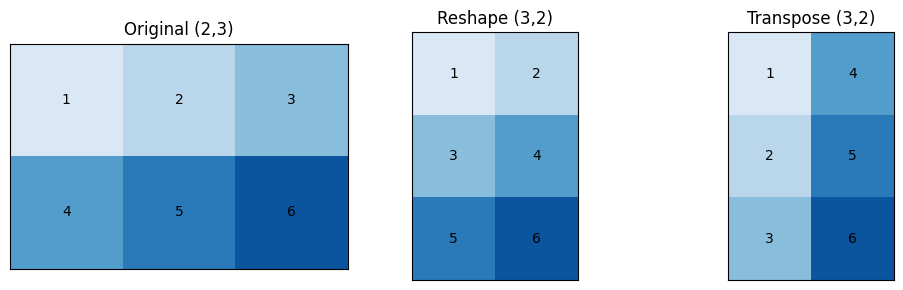

In [11]:
print('Reshape:\n', a_np.reshape(3, 2))
print('Transpose:\n', a_np.T)
print('TF transpose:\n', tf.transpose(a_tf).numpy())
print('Torch transpose:\n', a_pt.transpose(0, 1))

fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, values, title in zip(axes, [a_np, a_np.reshape(3, 2), a_np.T],
                            ['Original (2,3)', 'Reshape (3,2)', 'Transpose (3,2)']):
    ax.imshow(values, cmap='Blues', vmin=0, vmax=7)
    for (i, j), value in np.ndenumerate(values):
        ax.text(j, i, str(value), ha='center', va='center')
    ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

### ترتیب محورهای تصویر

برای batch تصویرها، TensorFlow معمولاً `(B,H,W,C)` و لایه‌های تصویری PyTorch معمولاً `(B,C,H,W)` می‌خواهند.
`B` تعداد تصویر، `H` ارتفاع، `W` عرض و `C` تعداد کانال است.
برای تبدیل این دو قرارداد باید محور‌ها را جابه‌جا کنیم؛ reshape برای این کار درست نیست.

In [12]:
images = np.arange(2 * 4 * 5 * 3).reshape(2, 4, 5, 3)
images_np = np.transpose(images, (0, 3, 1, 2))
images_tf = tf.transpose(tf.constant(images), (0, 3, 1, 2))
images_pt = torch.tensor(images).permute(0, 3, 1, 2)

print('BHWC:', images.shape, 'BCHW:', images_pt.shape)
np.testing.assert_array_equal(images_np, images_tf.numpy())
np.testing.assert_array_equal(images_np, images_pt.numpy())
print('All three axis conversions agree.')

BHWC: (2, 4, 5, 3) BCHW: torch.Size([2, 3, 4, 5])
All three axis conversions agree.


## ۱۰. کنار هم گذاشتن: concatenate و stack

`concatenate` یا `cat` روی یک محور موجود ادامه می‌دهد.
`stack` یک محور جدید می‌سازد. دو بردار ۳تایی با concatenate به ۶ عنصر و با stack به شکل `(2,3)` می‌رسند.

In [13]:
print('Concatenate:')
print(np.concatenate([v_np, v_np], axis=0))
print(tf.concat([v_tf, v_tf], axis=0))
print(torch.cat([v_pt, v_pt], dim=0))

print('Stack shapes:')
print(np.stack([v_np, v_np], axis=0).shape)
print(tf.stack([v_tf, v_tf], axis=0).shape)
print(torch.stack([v_pt, v_pt], dim=0).shape)

Concatenate:
[1. 2. 3. 1. 2. 3.]
tf.Tensor([1. 2. 3. 1. 2. 3.], shape=(6,), dtype=float32)
tensor([1., 2., 3., 1., 2., 3.])
Stack shapes:
(2, 3)
(2, 3)
torch.Size([2, 3])


## ۱۱. محاسبهٔ عنصر‌به‌عنصر و ضرب ماتریسی

عملگرهای `+`، `-`، `*`، `/` و `**` روی هر عنصر عمل می‌کنند.
`*` ضرب ماتریسی نیست. برای ضرب ماتریسی از `@` استفاده می‌کنیم:

$$A_{2\times3}\ @\ B_{3\times2}=C_{2\times2}.$$

اندازهٔ داخلی باید برابر باشد؛ در این مثال هر دو برابر ۳ است.

In [14]:
print('Elementwise × 2:')
print(a_np * 2, '\n', a_tf * 2, '\n', a_pt * 2)

b_np = np.array([[1, 0], [0, 1], [1, 1]])
b_tf = tf.constant(b_np, dtype=a_tf.dtype)
b_pt = torch.tensor(b_np, dtype=a_pt.dtype)
print('Matrix product:')
print(a_np @ b_np)
print(a_tf @ b_tf)
print(a_pt @ b_pt)

Elementwise × 2:
[[ 2  4  6]
 [ 8 10 12]] 
 tf.Tensor(
[[ 2  4  6]
 [ 8 10 12]], shape=(2, 3), dtype=int32) 
 tensor([[ 2,  4,  6],
        [ 8, 10, 12]])
Matrix product:
[[ 4  5]
 [10 11]]
tf.Tensor(
[[ 4  5]
 [10 11]], shape=(2, 2), dtype=int32)
tensor([[ 4,  5],
        [10, 11]])


## ۱۲. جمع، میانگین و argmax

در ماتریس، `axis=0` سطرها را جمع می‌کند و برای هر ستون یک مقدار می‌دهد.
`axis=1` ستون‌ها را جمع می‌کند و برای هر سطر یک مقدار می‌دهد. در PyTorch نام این ورودی `dim` است.
با `keepdims=True` یا `keepdim=True` محور حذف نمی‌شود و اندازه‌اش ۱ می‌شود.
`argmax` شمارهٔ محل بزرگ‌ترین مقدار را برمی‌گرداند.

In [15]:
print('Column sums:', a_np.sum(axis=0), tf.reduce_sum(a_tf, axis=0), a_pt.sum(dim=0))
print('Row sums:', a_np.sum(axis=1), tf.reduce_sum(a_tf, axis=1), a_pt.sum(dim=1))
print('Row means:', f_np.mean(axis=1), tf.reduce_mean(f_tf, axis=1), f_pt.mean(dim=1))
print('Keep dimension:', a_np.sum(axis=1, keepdims=True).shape,
      tf.reduce_sum(a_tf, axis=1, keepdims=True).shape, a_pt.sum(dim=1, keepdim=True).shape)
print('Argmax per row:', a_np.argmax(axis=1), tf.argmax(a_tf, axis=1), a_pt.argmax(dim=1))

Column sums: [5 7 9] tf.Tensor([5 7 9], shape=(3,), dtype=int32) tensor([5, 7, 9])
Row sums: [ 6 15] tf.Tensor([ 6 15], shape=(2,), dtype=int32) tensor([ 6, 15])
Row means: [2. 5.] tf.Tensor([2. 5.], shape=(2,), dtype=float32) tensor([2., 5.])
Keep dimension: (2, 1) (2, 1) torch.Size([2, 1])
Argmax per row: [2 2] tf.Tensor([2 2], shape=(2,), dtype=int64) tensor([2, 2])


## ۱۳. Broadcasting

با broadcasting، بعضی محاسبات روی آرایه‌های دارای شکل متفاوت انجام می‌شوند.
اندازه‌ها از راست مقایسه می‌شوند: هر دو اندازه باید برابر باشند یا یکی از آن‌ها ۱ باشد.
افزودن بردار `(3,)` به ماتریس `(2,3)` همان بردار را به هر سطر اضافه می‌کند.

[[11 22 33]
 [14 25 36]] 
 tf.Tensor(
[[11 22 33]
 [14 25 36]], shape=(2, 3), dtype=int32) 
 tensor([[11, 22, 33],
        [14, 25, 36]])


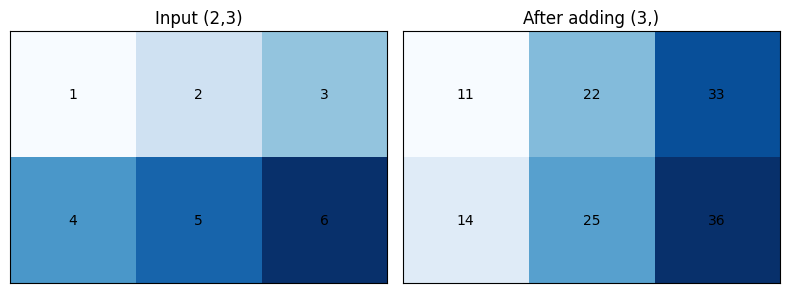

In [16]:
offset_np = np.array([10, 20, 30])
result_np = a_np + offset_np
result_tf = a_tf + tf.constant([10, 20, 30], dtype=a_tf.dtype)
result_pt = a_pt + torch.tensor([10, 20, 30], dtype=a_pt.dtype)

print(result_np, '\n', result_tf, '\n', result_pt)
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
for ax, values, title in zip(axes, [a_np, result_np], ['Input (2,3)', 'After adding (3,)']):
    ax.imshow(values, cmap='Blues')
    for (i, j), value in np.ndenumerate(values):
        ax.text(j, i, str(value), ha='center', va='center')
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

### یک اشتباه رایج در شکل خروجی

تفریق شکل `(3,1)` از `(3,)` خروجی `(3,3)` تولید می‌کند؛ این معمولاً برای محاسبهٔ خطای سه پیش‌بینی مورد نظر ما نیست.
قبل از محاسبهٔ loss، شکل پیش‌بینی و هدف را یکسان کنید.

In [17]:
prediction = torch.tensor([[1.], [2.], [3.]])
target = torch.tensor([1., 2., 3.])
print('Wrong shape:', (prediction - target).shape)
print('Correct shape:', (prediction.squeeze(1) - target).shape)
assert prediction.squeeze(1).shape == target.shape

Wrong shape: torch.Size([3, 3])
Correct shape: torch.Size([3])


## ۱۴. تبدیل بین NumPy و تنسورها

در اجرای معمول eager، برای TensorFlow از `.numpy()` استفاده می‌کنیم.
برای PyTorch، مسیر عمومی و صریح `tensor.detach().cpu().numpy()` است:
`detach` اتصال به محاسبهٔ گرادیان را قطع می‌کند و `cpu` داده را به CPU می‌آورد.
`item()` برای گرفتن یک عدد پایتونی از تنسور تک‌عنصری و `tolist()` برای گرفتن لیست مفید است.

In [18]:
array = np.array([1., 2., 3.], dtype=np.float32)
tensor_tf = tf.convert_to_tensor(array)
tensor_pt = torch.from_numpy(array)

print('Back to NumPy:', tensor_tf.numpy(), tensor_pt.detach().cpu().numpy())
print('One Python number:', tf.constant(5).numpy().item(), torch.tensor(5).item())
print('Python lists:', tensor_tf.numpy().tolist(), tensor_pt.tolist())

Back to NumPy: [1. 2. 3.] [1. 2. 3.]
One Python number: 5 5
Python lists: [1.0, 2.0, 3.0] [1.0, 2.0, 3.0]


## ۱۵. کپی و حافظهٔ مشترک

`torch.from_numpy` برای آرایهٔ CPU با نوع پشتیبانی‌شده حافظه را به اشتراک می‌گذارد.
تغییر یکی ممکن است دیگری را هم تغییر دهد. `torch.tensor(array)` یک کپی می‌سازد.
برای داشتن نسخهٔ مستقل در PyTorch از `clone()` و در NumPy از `copy()` استفاده کنید.
`detach()` به‌تنهایی کپی نیست؛ برای خروجی NumPy مستقل، در پایان `.copy()` اضافه کنید.

In [19]:
original = np.array([1., 2., 3.], dtype=np.float32)
shared = torch.from_numpy(original)
copied = torch.tensor(original)
original[0] = 99
print('NumPy:', original)
print('Shared torch tensor:', shared)
print('Copied torch tensor:', copied)

independent = shared.detach().cpu().numpy().copy()
shared[1] = 88
print('Independent NumPy copy:', independent)

NumPy: [99.  2.  3.]
Shared torch tensor: tensor([99.,  2.,  3.])
Copied torch tensor: tensor([1., 2., 3.])
Independent NumPy copy: [99.  2.  3.]


## ۱۶. تغییر مقدار: Tensor در برابر Variable

آرایهٔ NumPy و تنسور معمولی PyTorch قابل تغییرند.
در TensorFlow، محتوای `tf.Tensor` را درجا تغییر نمی‌دهیم؛ یک تنسور جدید می‌سازیم یا از `tf.Variable` استفاده می‌کنیم.
`Variable` برای مقدارهای تغییرپذیر، مانند وزن‌های مدل، کاربرد دارد.

In [20]:
mutable_np = np.array([1., 2.]); mutable_np[0] = 10.
mutable_pt = torch.tensor([1., 2.]); mutable_pt[0] = 10.
mutable_tf = tf.Variable([1., 2.]); mutable_tf[0].assign(10.)
print(mutable_np, mutable_pt, mutable_tf.numpy())

constant_tf = tf.constant([1., 2.])
new_tf = constant_tf + 1
print('Old TF tensor:', constant_tf.numpy(), 'new tensor:', new_tf.numpy())

[10.  2.] tensor([10.,  2.]) [10.  2.]
Old TF tensor: [1. 2.] new tensor: [2. 3.]


## ۱۷. تفاوت مهم با NumPy: گرادیان خودکار

NumPy برای محاسبات آرایه‌ای است و به‌تنهایی گراف گرادیان خودکار این دو کتابخانه را ندارد.
TensorFlow و PyTorch می‌توانند مشتق محاسبات را برای آموزش مدل به دست آورند.
برای مثال:

$$f(x)=x_1^2+x_2^2,\qquad \nabla f(x)=[2x_1,2x_2].$$

در نقطهٔ `[2,3]` جواب `[4,6]` است. تبدیل به NumPy در وسط محاسبه، مسیر مشتق‌گیری را قطع می‌کند.

In [21]:
x_np = np.array([2., 3.])
print('Manual NumPy gradient:', 2 * x_np)

x_tf = tf.Variable([2., 3.])
with tf.GradientTape() as tape:
    loss_tf = tf.reduce_sum(x_tf ** 2)
print('TF gradient:', tape.gradient(loss_tf, x_tf).numpy())

x_pt = torch.tensor([2., 3.], requires_grad=True)
loss_pt = (x_pt ** 2).sum()
loss_pt.backward()
print('Torch gradient:', x_pt.grad)

Manual NumPy gradient: [4. 6.]
TF gradient: [4. 6.]
Torch gradient: tensor([4., 6.])


### گرادیان PyTorch جمع می‌شود

اگر چند بار `backward` انجام دهید، گرادیان‌ها انباشته می‌شوند.
برای شروع محاسبهٔ جدید باید گرادیان قبلی پاک شود. در آموزش مدل معمولاً `optimizer.zero_grad()` این کار را می‌کند.
در مثال کوتاه زیر مستقیم از `x_pt.grad = None` استفاده می‌کنیم.

In [22]:
(x_pt ** 2).sum().backward()  # گراف جدید ساخته می‌شود
print('Accumulated gradient:', x_pt.grad)
x_pt.grad = None
(x_pt ** 2).sum().backward()
print('Fresh gradient:', x_pt.grad)

Accumulated gradient: tensor([ 8., 12.])
Fresh gradient: tensor([4., 6.])


## ۱۸. محل محاسبه و چند نکتهٔ عملی

NumPy معمولی روی CPU کار می‌کند. تنسورهای دو کتابخانه می‌توانند با پشتیبانی دستگاه و عملیات، روی GPU هم محاسبه شوند.
مثال‌های این درس به GPU نیاز ندارند. در PyTorch، `.to(device)` تنسور را روی دستگاه انتخاب‌شده قرار می‌دهد؛
در TensorFlow می‌توان محدودهٔ دستگاه را با `tf.device` مشخص کرد.

In [23]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
on_device = torch.tensor([1., 2.]).to(device)
print('Torch selected device:', on_device.device)
print('TF GPUs:', tf.config.list_physical_devices('GPU'))
with tf.device('/CPU:0'):
    on_cpu = tf.constant([1., 2.])
print('TF selected device:', on_cpu.device)

Torch selected device: cpu
TF GPUs: []
TF selected device: /job:localhost/replica:0/task:0/device:CPU:0


## ۱۹. خلاصهٔ تفاوت‌ها

| کار | NumPy | TensorFlow | PyTorch |
|---|---|---|---|
| تعریف | `np.array` | `tf.constant` | `torch.tensor` |
| شکل | `.shape` | `.shape` | `.shape` |
| تعداد عناصر | `.size` | `tf.size(x)` | `.numel()` |
| تغییر نوع | `.astype(...)` | `tf.cast(...)` | `.to(dtype)` |
| تغییر شکل | `.reshape(...)` | `tf.reshape(...)` | `.reshape(...)` |
| تغییر ترتیب محور | `np.transpose` | `tf.transpose` | `.permute(...)` |
| محور جدید | `np.expand_dims` | `tf.expand_dims` | `.unsqueeze(...)` |
| اتصال | `np.concatenate` | `tf.concat` | `torch.cat` |
| ساخت محور با اتصال | `np.stack` | `tf.stack` | `torch.stack` |
| میانگین سطرها | `x.mean(axis=1)` | `tf.reduce_mean(x, axis=1)` | `x.mean(dim=1)` |
| تبدیل به NumPy | خود آرایه است | `.numpy()` در eager | `.detach().cpu().numpy()` |
| تغییر مقدار | قابل تغییر | `tf.Variable` | قابل تغییر، با رعایت قواعد autograd |
| گرادیان خودکار | به‌تنهایی ندارد | `GradientTape` | `backward` |

برای شروع، همین عملیات کافی‌اند. در مدل‌ها همیشه اول شکل، نوع و محل داده را بررسی کنید.

## ۲۰. تمرین کوتاه با پاسخ

۱. اعداد ۰ تا ۱۱ را به شکل `(3,4)` بسازید و میانگین هر سطر را حساب کنید.

۲. یک محور batch اضافه کنید تا شکل `(1,3,4)` شود.

۳. آرایه را به `float32` تبدیل کنید و در هر دو کتابخانه همان محاسبه را انجام دهید.

In [24]:
exercise_np = np.arange(12, dtype=np.float32).reshape(3, 4)
exercise_tf = tf.constant(exercise_np)
exercise_pt = torch.tensor(exercise_np)

print('Means:', exercise_np.mean(axis=1))
print('Means:', tf.reduce_mean(exercise_tf, axis=1).numpy())
print('Means:', exercise_pt.mean(dim=1))
print('With batch:', exercise_np[None].shape, tf.expand_dims(exercise_tf, 0).shape,
      exercise_pt.unsqueeze(0).shape)
np.testing.assert_allclose(exercise_np.mean(1), exercise_tf.numpy().mean(1))
np.testing.assert_allclose(exercise_np.mean(1), exercise_pt.mean(1).numpy())

Means: [1.5 5.5 9.5]
Means: [1.5 5.5 9.5]
Means: tensor([1.5000, 5.5000, 9.5000])
With batch: (1, 3, 4) (1, 3, 4) torch.Size([1, 3, 4])


## منابع رسمی


- [راهنمای Tensorهای TensorFlow](https://www.tensorflow.org/guide/tensor)
- [آموزش مقدماتی Tensor در PyTorch](https://docs.pytorch.org/tutorials/beginner/basics/tensorqs_tutorial.html)
- [حافظهٔ مشترک torch.from_numpy](https://docs.pytorch.org/docs/2.9/generated/torch.from_numpy.html)
- [کپی و view در NumPy](https://numpy.org/doc/stable/user/basics.copies.html)
- [آموزش مشتق‌گیری TensorFlow](https://www.tensorflow.org/guide/autodiff)


بازبینی منابع و اجرای این درس: ۱۶ اکتبر ۲۰۲۶.